# TA-07: Simulasi Dinamika Suhu Ruangan dengan Pemanas

**Mata Praktikum:** Pemodelan dan Simulasi
**Dosen Pengampu:** Mohammad Bayu Anggara, S.Kom., M.Kom.
**Nama / NIM:** (isi nama lengkap) / 301240041
**Kelas:** 4B Teknik Informatika, Universitas Bale Bandung

## Tujuan
1. Menerjemahkan konsep stock, flow, dan feedback loop ke dalam persamaan diferensial.
2. Mengimplementasikan metode Euler di Python untuk mensimulasikan suhu ruangan.
3. Memvalidasi dan mengkalibrasi model memakai dataset dan solusi analitik.
4. Menganalisis perilaku sistem lewat skenario What-If.

## Studi Kasus
Sebuah ruangan dipanaskan oleh pemanas. Awalnya suhu ruangan sama dengan suhu luar.
Setelah pemanas menyala, suhu naik. Makin tinggi suhu ruangan, makin banyak panas yang
hilang ke luar, sehingga kenaikan suhu melambat dan akhirnya berhenti di suhu stabil
(steady state). Studi kasus ini lanjutan dari TP-07.

## 1. Formulasi Model Matematika

**Struktur Stock-Flow**
- Stock: energi panas (diukur lewat suhu ruangan T)
- Inflow: daya pemanas Q_heater
- Outflow: kehilangan panas UA * (T - T_luar)
- Feedback loop: negatif (balancing). Suhu naik, kehilangan panas naik, kenaikan suhu melambat.

**Persamaan Diferensial** (kesetimbangan energi)

$$C \frac{dT}{dt} = Q_{heater} - UA\,(T - T_{luar})$$

$$\frac{dT}{dt} = \frac{1}{C}\left[Q_{heater} - UA\,(T - T_{luar})\right]$$

**Metode Euler**

$$T_{k+1} = T_k + \Delta t \cdot \frac{dT}{dt}\bigg|_k$$

**Steady state** (dT/dt = 0) dan konstanta waktu:

$$T_{ss} = T_{luar} + \frac{Q_{heater}}{UA} \qquad \tau = \frac{C}{UA}$$

**Solusi analitik** (untuk pembanding, kalau Q dan T_luar konstan):

$$T(t) = T_{ss} + (T_0 - T_{ss})\,e^{-t/\tau}$$

**Asumsi**
- Suhu seragam di seluruh ruangan, jadi modelnya ODE (bukan PDE).
- C dan UA konstan.
- Tidak ada sumber panas lain (orang, peralatan).

**Parameter** (sintetis, dari TP-07)

| Parameter | Simbol | Nilai | Satuan |
|---|---|---|---|
| Kapasitas panas ruangan | C | 50.000 | J/K |
| Koefisien kehilangan panas | UA | 20 | W/K |
| Daya pemanas | Q_heater | 200 | W |
| Suhu awal ruangan | T(0) | 28 | °C |
| Suhu luar | T_luar | 28 | °C |
| Selang waktu | Δt | 10 | s |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ---------- Parameter baseline (sama dengan TP-07) ----------
C        = 50_000   # kapasitas panas ruangan (J/K)
UA       = 20       # koefisien kehilangan panas (W/K)
Q_HEATER = 200      # daya pemanas (W)
T0       = 28.0     # suhu awal ruangan (C)
T_LUAR   = 28.0     # suhu luar (C)
DT       = 10       # selang waktu Euler (s)

TAU  = C / UA                    # konstanta waktu (s)
T_SS = T_LUAR + Q_HEATER / UA    # suhu steady state (C)
T_END = 4 * 3600                 # lama simulasi: 4 jam (s), sekitar 5.7 kali tau

print(f"Konstanta waktu tau = {TAU:.0f} s = {TAU/60:.1f} menit")
print(f"Suhu steady state   = {T_SS:.1f} C")
print(f"Syarat kestabilan Euler: dt < 2*tau = {2*TAU:.0f} s (dt kita {DT} s, aman)")

Konstanta waktu tau = 2500 s = 41.7 menit
Suhu steady state   = 38.0 C
Syarat kestabilan Euler: dt < 2*tau = 5000 s (dt kita 10 s, aman)


In [2]:
def euler_simulasi(T_awal, t_end, dt, C, UA, Q_fn, Tluar_fn):
    """Simulasi suhu ruangan dengan metode Euler.
    Q_fn(t) dan Tluar_fn(t) adalah fungsi waktu, jadi bisa konstan, step, atau sinusoida."""
    n = int(round(t_end / dt))
    t = np.arange(n + 1) * dt
    T = np.zeros(n + 1)
    T[0] = T_awal
    for k in range(n):
        dTdt = (Q_fn(t[k]) - UA * (T[k] - Tluar_fn(t[k]))) / C
        T[k + 1] = T[k] + dt * dTdt
    return t, T


def solusi_analitik(t, T_awal, T_ss, tau):
    return T_ss + (T_awal - T_ss) * np.exp(-t / tau)


# Input konstan untuk baseline
Q_const     = lambda t: Q_HEATER
Tluar_const = lambda t: T_LUAR

In [3]:
# Hitung manual 3 langkah awal (untuk dicek ke hasil kode)
T_manual = [T0]
for k in range(3):
    dTdt = (Q_HEATER - UA * (T_manual[-1] - T_LUAR)) / C
    T_baru = T_manual[-1] + DT * dTdt
    print(f"Langkah {k+1}: dT/dt = {dTdt:.6f} K/s -> T = {T_baru:.5f} C")
    T_manual.append(T_baru)

# Hasil yang diharapkan: 28.04000, 28.07984, 28.11952

Langkah 1: dT/dt = 0.004000 K/s -> T = 28.04000 C
Langkah 2: dT/dt = 0.003984 K/s -> T = 28.07984 C
Langkah 3: dT/dt = 0.003968 K/s -> T = 28.11952 C


In [4]:
t_base, T_base = euler_simulasi(T0, T_END, DT, C, UA, Q_const, Tluar_const)

df_base = pd.DataFrame({
    "Waktu (s)": t_base,
    "Waktu (menit)": t_base / 60,
    "Suhu T (C)": T_base,
    "Q_heater (W)": Q_HEATER,
    "T_luar (C)": T_LUAR,
})
print(df_base.head())
print(f"\nSuhu akhir simulasi : {T_base[-1]:.3f} C")
print(f"Suhu steady state teori: {T_SS:.3f} C")
print(f"Selisih              : {abs(T_base[-1] - T_SS):.4f} C")

# Suhu saat t = tau seharusnya sekitar 63.2% dari kenaikan total
idx_tau = int(TAU / DT)
print(f"\nT saat t = tau ({TAU:.0f} s): {T_base[idx_tau]:.2f} C "
      f"(teori: {T_SS + (T0 - T_SS)*np.exp(-1):.2f} C)")

   Waktu (s)  Waktu (menit)  Suhu T (C)  Q_heater (W)  T_luar (C)
0          0       0.000000   28.000000           200        28.0
1         10       0.166667   28.040000           200        28.0
2         20       0.333333   28.079840           200        28.0
3         30       0.500000   28.119521           200        28.0
4         40       0.666667   28.159043           200        28.0

Suhu akhir simulasi : 37.969 C
Suhu steady state teori: 38.000 C
Selisih              : 0.0311 C

T saat t = tau (2500 s): 34.33 C (teori: 34.32 C)


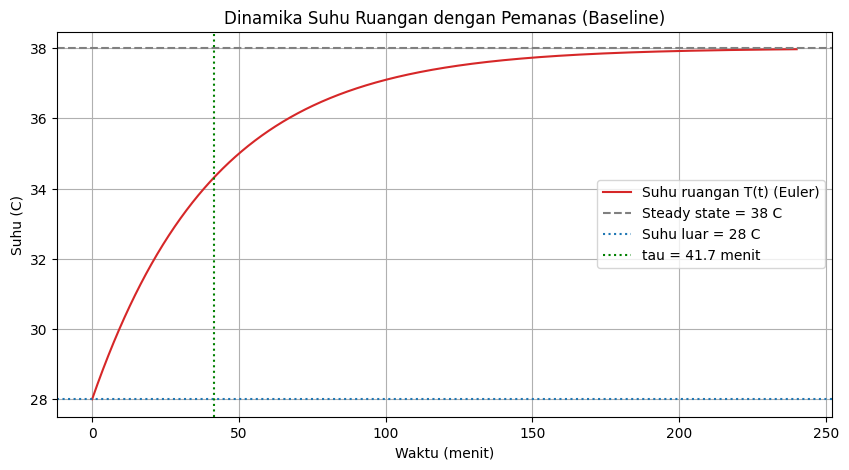

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(t_base / 60, T_base, color="tab:red", label="Suhu ruangan T(t) (Euler)")
plt.axhline(T_SS, color="gray", linestyle="--", label=f"Steady state = {T_SS:.0f} C")
plt.axhline(T_LUAR, color="tab:blue", linestyle=":", label=f"Suhu luar = {T_LUAR:.0f} C")
plt.axvline(TAU / 60, color="green", linestyle=":", label=f"tau = {TAU/60:.1f} menit")
plt.title("Dinamika Suhu Ruangan dengan Pemanas (Baseline)")
plt.xlabel("Waktu (menit)")
plt.ylabel("Suhu (C)")
plt.legend()
plt.grid(True)
plt.savefig("static/img/grafik_baseline.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretasi Grafik Baseline
Suhu ruangan naik cepat di awal lalu makin landai dan mendatar di sekitar 38 C. Bentuknya
seperti kurva eksponensial yang mendekati batas (goal-seeking), bukan eksponensial yang
naik terus dan bukan osilasi. Pola ini muncul karena feedback loop-nya negatif: makin
tinggi suhu ruangan, makin besar panas yang hilang ke luar (UA*(T - T_luar)), sehingga
selisih antara panas masuk dan panas keluar mengecil sampai nol di steady state.
Dengan tau = C/UA = 2.500 s (sekitar 42 menit), suhu sudah mencapai sekitar 63% dari
kenaikan totalnya pada menit ke-42 dan hampir stabil setelah sekitar 3 jam.

Galat maksimum Euler (dt=10s) : 0.007370 C
Galat maksimum solve_ivp        : 7.22e-08 C


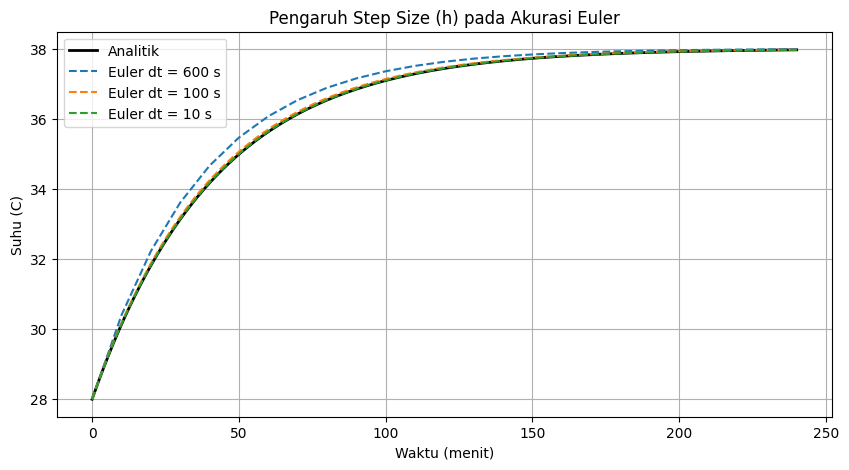

In [ ]:
# --- Solusi analitik ---
T_analitik = solusi_analitik(t_base, T0, T_SS, TAU)

# --- solve_ivp (solver SciPy) ---
def model_ode(t, y):
    return [(Q_HEATER - UA * (y[0] - T_LUAR)) / C]

sol = solve_ivp(model_ode, (0, T_END), [T0], t_eval=t_base, rtol=1e-8, atol=1e-10)

err_euler = np.abs(T_base - T_analitik)
err_ivp   = np.abs(sol.y[0] - T_analitik)
print(f"Galat maksimum Euler (dt={DT}s) : {err_euler.max():.6f} C")
print(f"Galat maksimum solve_ivp        : {err_ivp.max():.2e} C")

# --- Pengaruh step size ---
plt.figure(figsize=(10, 5))
plt.plot(t_base / 60, T_analitik, "k-", linewidth=2, label="Analitik")
for dt_uji in [600, 100, 10]:
    t_u, T_u = euler_simulasi(T0, T_END, dt_uji, C, UA, Q_const, Tluar_const)
    plt.plot(t_u / 60, T_u, "--", label=f"Euler dt = {dt_uji} s")
plt.title("Pengaruh Step Size (h) pada Akurasi Euler")
plt.xlabel("Waktu (menit)")
plt.ylabel("Suhu (C)")
plt.legend()
plt.grid(True)
plt.savefig("static/img/grafik_validasi_stepsize.png", dpi=150, bbox_inches="tight")
plt.show()

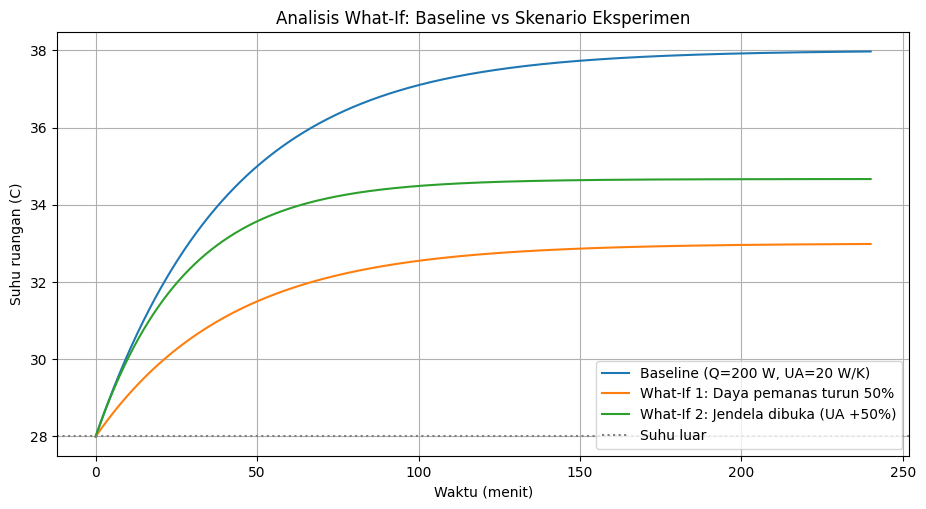

,Skenario,Q (W),UA (W/K),T_ss teori (C),T akhir sim (C),tau (menit)
0,"Baseline (Q=200 W, UA=20 W/K)",200,20,38.00,37.97,41.7
1,What-If 1: Daya pemanas turun 50%,100,20,33.00,32.98,41.7
2,What-If 2: Jendela dibuka (UA +50%),200,30,34.67,34.67,27.8


In [ ]:
skenario = {
    "Baseline (Q=200 W, UA=20 W/K)":      dict(Q=200, UA=20),
    "What-If 1: Daya pemanas turun 50%":  dict(Q=100, UA=20),
    "What-If 2: Jendela dibuka (UA +50%)": dict(Q=200, UA=30),
}

plt.figure(figsize=(11, 5.5))
hasil = []
for nama, p in skenario.items():
    t_s, T_s = euler_simulasi(T0, T_END, DT, C, p["UA"],
                              lambda t, q=p["Q"]: q, Tluar_const)
    Tss_s = T_LUAR + p["Q"] / p["UA"]
    tau_s = C / p["UA"]
    hasil.append({"Skenario": nama, "Q (W)": p["Q"], "UA (W/K)": p["UA"],
                  "T_ss teori (C)": round(Tss_s, 2),
                  "T akhir sim (C)": round(T_s[-1], 2),
                  "tau (menit)": round(tau_s / 60, 1)})
    plt.plot(t_s / 60, T_s, label=nama)

plt.axhline(T_LUAR, color="gray", linestyle=":", label="Suhu luar")
plt.title("Analisis What-If: Baseline vs Skenario Eksperimen")
plt.xlabel("Waktu (menit)")
plt.ylabel("Suhu ruangan (C)")
plt.legend()
plt.grid(True)
plt.savefig("static/img/grafik_whatif.png", dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame(hasil)

### Interpretasi Skenario What-If
- **Daya pemanas turun 50% (100 W):** suhu stabil turun dari 38 C menjadi 33 C
  (T_ss = 28 + 100/20). Kecepatan responsnya tetap sama karena tau = C/UA tidak
  berubah, jadi hanya "tingkat" suhu akhirnya yang bergeser.
- **Jendela dibuka (UA naik 50% jadi 30 W/K):** suhu stabil turun menjadi sekitar 34,7 C
  dan sistem lebih cepat mencapai steady state (tau turun dari 41,7 menit jadi 27,8 menit).
  Panas lebih banyak terbuang, jadi pemanas "kalah" lebih cepat dan kenaikan suhu
  tertahan di level yang lebih rendah.
- Dari kedua skenario terlihat bahwa Q_heater menentukan seberapa tinggi suhu akhir,
  sedangkan UA memengaruhi suhu akhir sekaligus kecepatan respons.

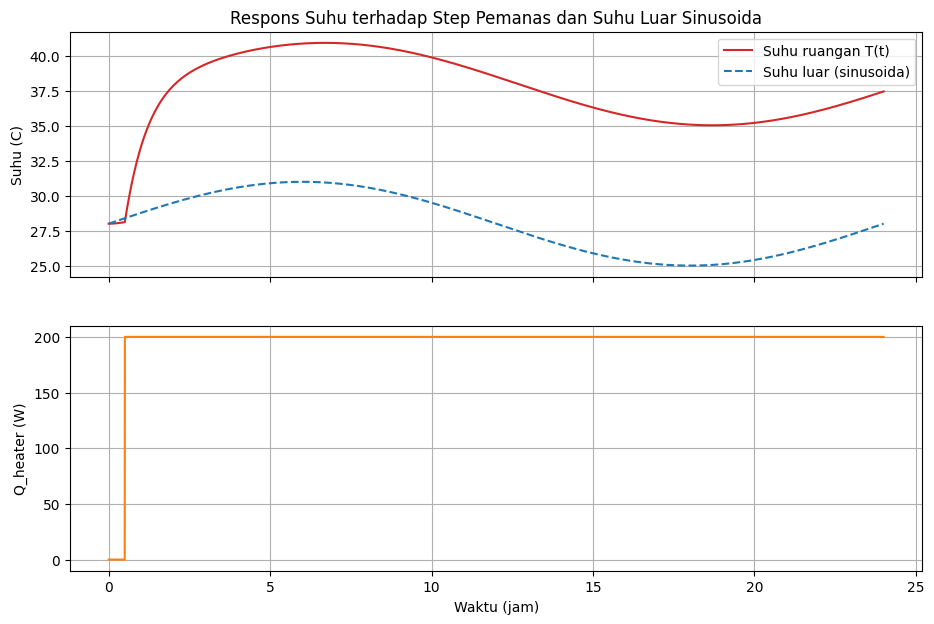

In [ ]:
T_END_24 = 24 * 3600   # simulasi 24 jam

# --- Sinyal uji: pemanas menyala tiba-tiba (step) pada menit ke-30 ---
Q_step = lambda t: 0.0 if t < 1800 else Q_HEATER

# --- Gangguan: suhu luar sinusoida (amplitudo 3 C, periode 24 jam) ---
Tluar_sin = lambda t: T_LUAR + 3.0 * np.sin(2 * np.pi * t / 86400)

t_u, T_u = euler_simulasi(T0, T_END_24, DT, C, UA, Q_step, Tluar_sin)
Q_plot = np.array([Q_step(x) for x in t_u])
Tluar_plot = np.array([Tluar_sin(x) for x in t_u])

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax[0].plot(t_u / 3600, T_u, color="tab:red", label="Suhu ruangan T(t)")
ax[0].plot(t_u / 3600, Tluar_plot, color="tab:blue", linestyle="--", label="Suhu luar (sinusoida)")
ax[0].set_ylabel("Suhu (C)")
ax[0].set_title("Respons Suhu terhadap Step Pemanas dan Suhu Luar Sinusoida")
ax[0].legend(); ax[0].grid(True)

ax[1].plot(t_u / 3600, Q_plot, color="tab:orange")
ax[1].set_ylabel("Q_heater (W)")
ax[1].set_xlabel("Waktu (jam)")
ax[1].grid(True)
plt.savefig("static/img/grafik_step_sinusoida.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretasi Respons Step dan Sinusoida
Sebelum pemanas menyala (30 menit pertama), suhu ruangan hanya mengikuti suhu luar.
Setelah Q_heater menyala 200 W, suhu naik mengikuti kurva yang sama seperti baseline,
tetapi tetap bergoyang mengikuti suhu luar yang naik turun. Garis suhu ruangan tertinggal
sedikit di belakang suhu luar (ada lag) karena ruangan punya kapasitas panas C yang
meredam perubahan. Ini menunjukkan sistem bekerja seperti filter low-pass: perubahan
cepat di luar teredam, perubahan lambat tetap terlihat.

## 5. Validasi dan Kalibrasi dengan Dataset Kaggle

**Dataset:** Temperature Readings: IoT Devices
https://www.kaggle.com/datasets/atulanandjha/temperature-readings-iot-devices

Dataset berisi catatan suhu dari sensor IoT di sebuah ruangan (`Room Admin`). Tiap baris adalah satu
pembacaan suhu, dengan kolom `id`, `room_id/id`, `noted_date` (waktu pencatatan), `temp` (suhu, °C),
dan `out/in` (sensor di luar atau di dalam ruangan).

**Letak file:** taruh `IOT-temp.csv` di folder yang sama dengan notebook ini, atau di folder `data/`.
Kalau dijalankan di Google Colab dan file belum ada, notebook akan meminta upload otomatis.

**Cara dataset dipakai di model**
- Suhu luar (`out`) menjadi input gangguan T_luar(t).
- Suhu dalam (`in`) menjadi data pembanding untuk hasil simulasi.
- Dataset tidak punya data daya pemanas, jadi parameter C, UA, dan daya bersih Q dikalibrasi dari data.

In [9]:
from pathlib import Path

def cari_file(nama="IOT-temp.csv"):
    for p in [Path(nama), Path("data") / nama, Path("/content") / nama]:
        if p.exists():
            return p
    try:
        from google.colab import files      # khusus Google Colab
        print("File belum ada, silakan upload", nama)
        files.upload()
        return Path(nama)
    except ImportError:
        raise FileNotFoundError(
            f"{nama} tidak ditemukan. Letakkan di folder yang sama dengan notebook "
            f"atau di folder data/. Folder kerja saat ini: {Path.cwd()}"
        )

path_iot = cari_file()
df_iot = pd.read_csv(path_iot)
print("File dipakai:", path_iot.resolve())
df_iot.head(10)

File dipakai: C:\TA7_PDS\TA07-suhu-ruangan\data\IOT-temp.csv


,id,room_id/id,noted_date,temp,out/in
0,__export__.temp_log_196134_bd201015,Room Admin,08-12-2018 09:30,29,In
1,__export__.temp_log_196131_7bca51bc,Room Admin,08-12-2018 09:30,29,In
2,__export__.temp_log_196127_522915e3,Room Admin,08-12-2018 09:29,41,Out
3,__export__.temp_log_196128_be0919cf,Room Admin,08-12-2018 09:29,41,Out
4,__export__.temp_log_196126_d30b72fb,Room Admin,08-12-2018 09:29,31,In
5,__export__.temp_log_196125_b0fa0b41,Room Admin,08-12-2018 09:29,31,In
6,__export__.temp_log_196121_01544d45,Room Admin,08-12-2018 09:28,29,In
7,__export__.temp_log_196122_f8b80a9f,Room Admin,08-12-2018 09:28,29,In
8,__export__.temp_log_196111_6b7a0848,Room Admin,08-12-2018 09:26,29,In
9,__export__.temp_log_196112_e134aebd,Room Admin,08-12-2018 09:26,29,In


In [10]:
# ---------- EDA dasar ----------
print("Ukuran dataset  :", df_iot.shape, "(baris, kolom)")
print("\nTipe data:")
print(df_iot.dtypes)
print("\nMissing values per kolom:")
print(df_iot.isnull().sum())

df_iot["waktu"] = pd.to_datetime(df_iot["noted_date"], format="%d-%m-%Y %H:%M")
df_iot["posisi"] = df_iot["out/in"].str.strip().str.lower()   # 'in' atau 'out'
print("\nID duplikat     :", df_iot["id"].duplicated().sum())
df_iot = df_iot.drop_duplicates(subset="id")

print("Rentang waktu   :", df_iot["waktu"].min(), "sampai", df_iot["waktu"].max())
print("\nJumlah pembacaan per posisi sensor:")
print(df_iot["posisi"].value_counts())
print("\nStatistik suhu per posisi sensor:")
df_iot.groupby("posisi")["temp"].describe().round(2)

Ukuran dataset  : (97606, 5) (baris, kolom)

Tipe data:
id            object
room_id/id    object
noted_date    object
temp           int64
out/in        object
dtype: object

Missing values per kolom:
id            0
room_id/id    0
noted_date    0
temp          0
out/in        0
dtype: int64

ID duplikat     : 1
Rentang waktu   : 2018-07-28 07:06:00 sampai 2018-12-08 09:30:00

Jumlah pembacaan per posisi sensor:
posisi
out    77260
in     20345
Name: count, dtype: int64

Statistik suhu per posisi sensor:


,count,mean,std,min,25%,50%,75%,max
posisi,,,,,,,,
in,20345.0,30.45,2.24,21.0,29.0,31.0,32.0,41.0
out,77260.0,36.27,5.72,24.0,31.0,37.0,40.0,51.0


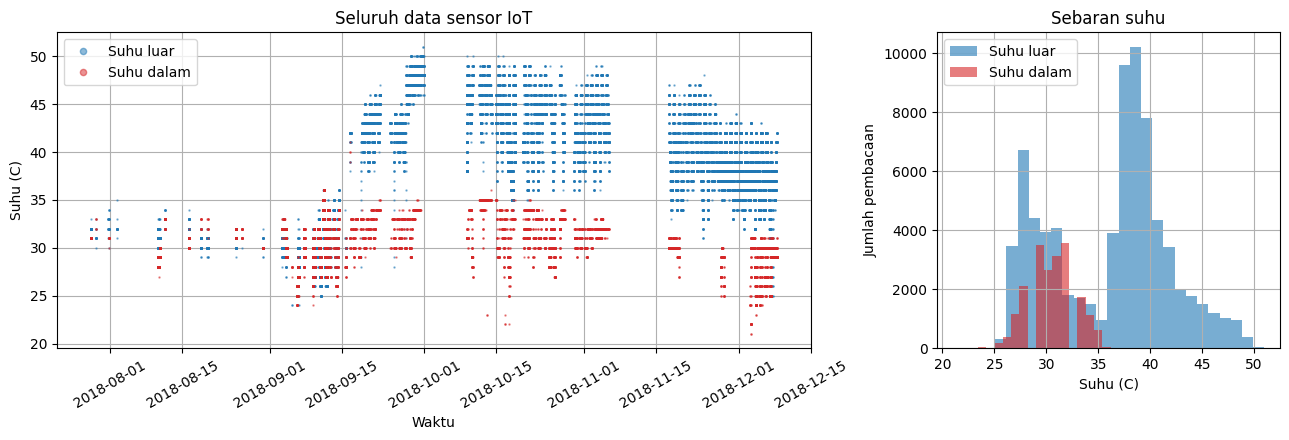

In [ ]:
# ---------- Visualisasi seluruh data ----------
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})
for nama, warna in [("out", "tab:blue"), ("in", "tab:red")]:
    sub = df_iot[df_iot["posisi"] == nama]
    ax[0].plot(sub["waktu"], sub["temp"], ".", markersize=1.5, color=warna, alpha=0.5,
               label="Suhu luar" if nama == "out" else "Suhu dalam")
    ax[1].hist(sub["temp"], bins=25, color=warna, alpha=0.6,
               label="Suhu luar" if nama == "out" else "Suhu dalam")
ax[0].set_title("Seluruh data sensor IoT")
ax[0].set_xlabel("Waktu"); ax[0].set_ylabel("Suhu (C)")
ax[0].legend(markerscale=6); ax[0].grid(True)
ax[0].tick_params(axis="x", rotation=30)
ax[1].set_title("Sebaran suhu")
ax[1].set_xlabel("Suhu (C)"); ax[1].set_ylabel("Jumlah pembacaan")
ax[1].legend(); ax[1].grid(True)
plt.tight_layout()
plt.savefig("static/img/grafik_dataset_eda.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretasi EDA
- Dataset berisi sekitar 97 ribu pembacaan dari Juli sampai Desember 2018, dengan jumlah pembacaan
  sensor luar jauh lebih banyak daripada sensor dalam.
- Suhu luar rata-rata sekitar 36 C (rentang 24 sampai 51 C, banyak di 36 sampai 45 C pada Oktober dan
  November), sedangkan suhu dalam rata-rata sekitar 30 C dan jauh lebih stabil. Jadi ruangan ini
  **lebih dingin dari lingkungan luarnya**, kemungkinan karena ada pendingin (AC).
- Pembacaan tidak merata sepanjang waktu (ada hari yang kosong). Karena itu simulasi tidak memakai
  seluruh data sekaligus, tetapi satu jendela waktu 48 jam dengan data paling rapat.

Jendela terpilih : 2018-11-17 10:30:00 sampai 2018-11-19 10:00:00
Jumlah titik     : 96 (tiap 30 menit), terisi asli 85 dari 96


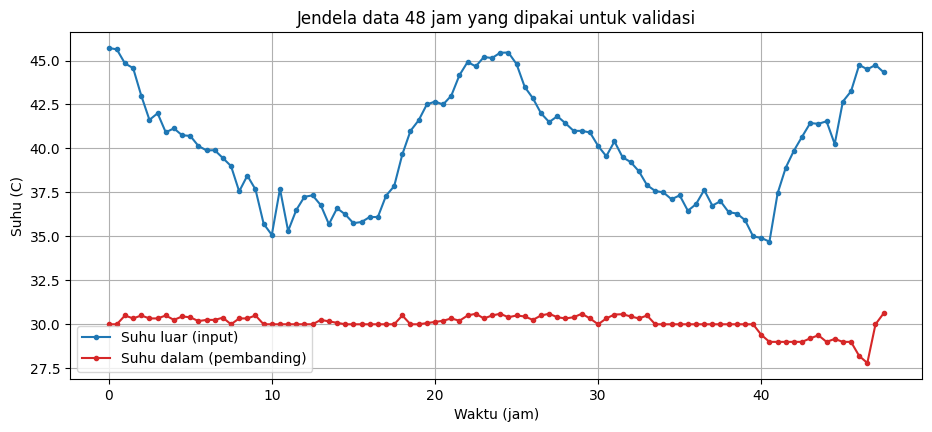


Suhu luar   : rata-rata 39.99 C, rentang 34.7 - 45.7 C
Suhu dalam  : rata-rata 30.04 C, simpangan baku 0.52 C
Korelasi suhu luar vs dalam: 0.09


In [ ]:
# ---------- Persiapan data: rata-rata tiap 30 menit, lalu pilih jendela 48 jam terpadat ----------
luar_30  = df_iot[df_iot["posisi"] == "out"].set_index("waktu")["temp"].resample("30min").mean()
dalam_30 = df_iot[df_iot["posisi"] == "in" ].set_index("waktu")["temp"].resample("30min").mean()
gab = pd.concat([luar_30.rename("luar"), dalam_30.rename("dalam")], axis=1)

ada = gab.notna().all(axis=1).astype(int)          # 1 = sensor luar dan dalam sama-sama punya data
isi_48jam = ada.rolling(96).sum()                  # 96 bin x 30 menit = 48 jam
akhir = isi_48jam.idxmax()
awal  = akhir - pd.Timedelta(hours=47, minutes=30)

seg = gab.loc[awal:akhir].interpolate(limit=4).dropna()    # tambal celah kecil (maks. 2 jam)
print(f"Jendela terpilih : {seg.index[0]} sampai {seg.index[-1]}")
print(f"Jumlah titik     : {len(seg)} (tiap 30 menit), terisi asli {int(isi_48jam.max())} dari 96")

t_data      = (seg.index - seg.index[0]).total_seconds().values   # detik
Tluar_data  = seg["luar"].values
Tdalam_data = seg["dalam"].values

plt.figure(figsize=(11, 4.5))
plt.plot(t_data / 3600, Tluar_data, "o-", markersize=3, color="tab:blue", label="Suhu luar (input)")
plt.plot(t_data / 3600, Tdalam_data, "o-", markersize=3, color="tab:red", label="Suhu dalam (pembanding)")
plt.title("Jendela data 48 jam yang dipakai untuk validasi")
plt.xlabel("Waktu (jam)"); plt.ylabel("Suhu (C)")
plt.legend(); plt.grid(True)
plt.savefig("static/img/grafik_dataset_jendela.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\nSuhu luar   : rata-rata {Tluar_data.mean():.2f} C, rentang {Tluar_data.min():.1f} - {Tluar_data.max():.1f} C")
print(f"Suhu dalam  : rata-rata {Tdalam_data.mean():.2f} C, simpangan baku {Tdalam_data.std():.2f} C")
print(f"Korelasi suhu luar vs dalam: {np.corrcoef(Tluar_data, Tdalam_data)[0, 1]:.2f}")

In [13]:
# ---------- Model untuk validasi ----------
# dT/dt = (1/C) * [ Q_net - UA * (T - T_luar(t)) ]
# Q_net = daya bersih ke ruangan. Positif = pemanasan, negatif = pendinginan (misalnya AC).
# Di dataset ini suhu dalam lebih dingin dari luar, jadi Q_net diperkirakan negatif.
from scipy.optimize import least_squares

DT_VAL = 60.0                                     # step Euler untuk validasi (detik)
n_val  = int(t_data[-1] / DT_VAL)
t_grid = np.arange(n_val + 1) * DT_VAL
TL_grid = np.interp(t_grid, t_data, Tluar_data)   # suhu luar di tiap langkah Euler

def simulasi_val(C_, UA_, Q_):
    T = np.empty(n_val + 1)
    T[0] = Tdalam_data[0]
    for k in range(n_val):
        T[k + 1] = T[k] + DT_VAL * (Q_ - UA_ * (T[k] - TL_grid[k])) / C_
    return T

def prediksi(C_, UA_, Q_):
    return np.interp(t_data, t_grid, simulasi_val(C_, UA_, Q_))

def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

# ---------- Pembanding sebelum kalibrasi ----------
rmse_tp07  = rmse(prediksi(C, UA, Q_HEATER), Tdalam_data)   # parameter TP-07 (pemanas 200 W)
rmse_tanpa = rmse(prediksi(C, UA, 0.0),      Tdalam_data)   # tanpa pemanas
rmse_rata  = rmse(np.full_like(Tdalam_data, Tdalam_data.mean()), Tdalam_data)  # tebakan rata-rata konstan

# ---------- Kalibrasi C, UA, Q_net (least squares, beberapa titik awal) ----------
def residual(p):
    return prediksi(np.exp(p[0]), np.exp(p[1]), p[2]) - Tdalam_data

terbaik = None
for c0 in [3e4, 2e5, 1e6]:
    for u0 in [5, 20, 80]:
        hasil_fit = least_squares(
            residual, [np.log(c0), np.log(u0), -10 * u0],
            bounds=([np.log(5e3), np.log(1), -5000], [np.log(5e7), np.log(500), 2000]))
        if terbaik is None or hasil_fit.cost < terbaik.cost:
            terbaik = hasil_fit

C_fit, UA_fit, Q_fit = np.exp(terbaik.x[0]), np.exp(terbaik.x[1]), terbaik.x[2]
T_fit = prediksi(C_fit, UA_fit, Q_fit)
rmse_fit = rmse(T_fit, Tdalam_data)

tabel = pd.DataFrame({
    "Model": ["Parameter TP-07 (Q = +200 W)", "Tanpa pemanas (Q = 0)",
              "Tebakan rata-rata konstan", "Terkalibrasi (C, UA, Q_net)"],
    "RMSE (C)": [rmse_tp07, rmse_tanpa, rmse_rata, rmse_fit],
}).round(3)
print(tabel.to_string(index=False))
print(f"\nParameter terkalibrasi: C = {C_fit:,.0f} J/K | UA = {UA_fit:.2f} W/K | Q_net = {Q_fit:.1f} W")
print(f"Konstanta waktu tau = C/UA = {C_fit / UA_fit / 3600:.1f} jam")
print(f"Suhu steady state teori (T_luar rata-rata + Q_net/UA) = {Tluar_data.mean() + Q_fit / UA_fit:.2f} C")

                       Model  RMSE (C)
Parameter TP-07 (Q = +200 W)    19.769
       Tanpa pemanas (Q = 0)    10.110
   Tebakan rata-rata konstan     0.521
 Terkalibrasi (C, UA, Q_net)     0.448

Parameter terkalibrasi: C = 1,794,293 J/K | UA = 11.42 W/K | Q_net = -114.7 W
Konstanta waktu tau = C/UA = 43.7 jam
Suhu steady state teori (T_luar rata-rata + Q_net/UA) = 29.95 C


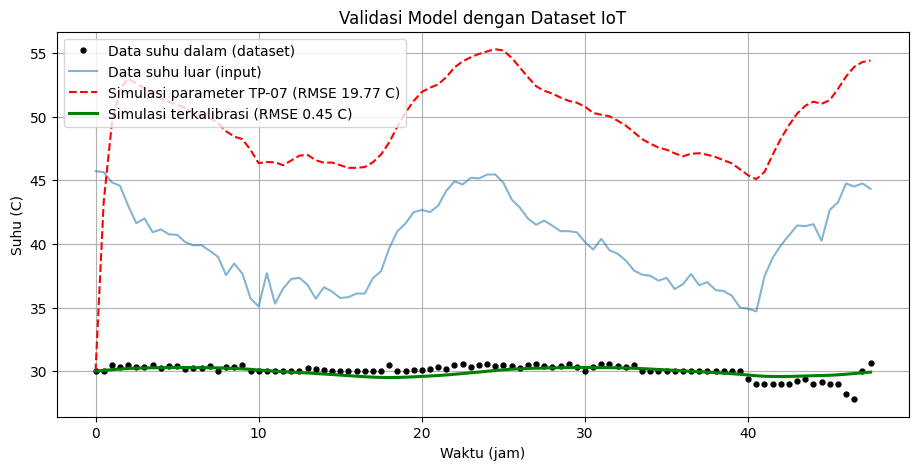

In [ ]:
# ---------- Grafik validasi ----------
T_tp07 = prediksi(C, UA, Q_HEATER)

plt.figure(figsize=(11, 5))
plt.plot(t_data / 3600, Tdalam_data, "ko", markersize=3.5, label="Data suhu dalam (dataset)")
plt.plot(t_data / 3600, Tluar_data, color="tab:blue", alpha=0.55, label="Data suhu luar (input)")
plt.plot(t_data / 3600, T_tp07, "r--", label=f"Simulasi parameter TP-07 (RMSE {rmse_tp07:.2f} C)")
plt.plot(t_data / 3600, T_fit, "g-", linewidth=2.2, label=f"Simulasi terkalibrasi (RMSE {rmse_fit:.2f} C)")
plt.title("Validasi Model dengan Dataset IoT")
plt.xlabel("Waktu (jam)"); plt.ylabel("Suhu (C)")
plt.legend(); plt.grid(True)
plt.savefig("static/img/grafik_validasi_dataset.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretasi Validasi
- Dengan parameter TP-07 (pemanas 200 W dan suhu awal sekitar 30 C), simulasi menyimpang jauh dari data
  karena model memanaskan ruangan menuju 40 C lebih, sedangkan suhu dalam di dataset tetap sekitar 30 C.
- Setelah dikalibrasi, daya bersih Q_net bernilai **negatif**. Artinya ruangan di dataset didinginkan
  (kemungkinan AC), bukan dipanaskan, sehingga suhunya tertahan di bawah suhu luar.
- RMSE terkalibrasi turun jauh dibanding parameter TP-07, tetapi hanya sedikit lebih baik dari tebakan
  rata-rata konstan. Penyebabnya, suhu dalam di dataset hampir tidak berubah dan korelasinya dengan suhu
  luar sangat rendah, sehingga dinamika model (naik lalu stabil) tidak tampak jelas di data ini.
- Jadi dataset ini cukup untuk memastikan **tingkat suhu stabil** model masuk akal, tetapi kurang kuat
  untuk menguji kecepatan respons (konstanta waktu) model.

## Kesimpulan
1. Model dT/dt = (1/C)[Q - UA(T - T_luar)] berhasil menggambarkan perilaku suhu ruangan yang naik
   lalu stabil (steady state) akibat feedback loop negatif.
2. Hasil simulasi Euler (dt = 10 s) sangat dekat dengan solusi analitik dan solve_ivp. Suhu akhir
   mendekati T_ss = 38 C, dan step size yang lebih kecil memberi akurasi lebih baik.
3. Skenario What-If menunjukkan Q_heater menentukan tingkat suhu akhir, sedangkan UA memengaruhi
   suhu akhir sekaligus kecepatan respons (tau).
4. Pada validasi dengan dataset IoT, kalibrasi C, UA, dan Q_net menurunkan RMSE dari sekitar 19,8 C
   (parameter TP-07) menjadi sekitar 0,45 C. Namun hasil ini hanya sedikit lebih baik dari tebakan
   rata-rata konstan (sekitar 0,52 C), karena suhu dalam di dataset hampir konstan.
   (cek angka ini dengan output notebook-mu)

## Keterbatasan
- Suhu ruangan dianggap seragam (model satu persamaan), padahal di dunia nyata ada gradien suhu.
- C dan UA dianggap konstan, padahal bisa berubah (misalnya pintu atau jendela dibuka).
- Dataset tidak memuat daya pemanas. Selain itu ruangan di dataset tampak didinginkan (lebih dingin
  dari luar), sehingga validasi harus memakai daya bersih Q_net yang bernilai negatif, berbeda dari
  skenario pemanas pada TP-07.
- Suhu dalam di dataset hampir konstan dan tidak berkorelasi kuat dengan suhu luar, sehingga dataset
  kurang bisa menguji dinamika (kecepatan respons) model.
- Validasi memakai satu jendela 48 jam dengan data terpadat, bukan seluruh data, karena pembacaan
  sensor tidak merata sepanjang waktu.